# Notebook 16c — Manuscript figures: turnover and change points on the two measures

Added November 2026 for the law review manuscript (Part IV.E and the supplement). The May 2026 draft reported "change points": periods in which a genre's conventional vocabulary shifted, found from the turnover of the genre's top-ranked elements on the composite score. The paper no longer ranks anything by the composite, so this notebook recomputes the analysis on each of the two measures, prevalence and distinctiveness, in the single figure style of `saf_style.py` (prevalence blue, distinctiveness red, everything else gray, black intervals and reference lines, upright plots, no figure titles).

**Rules (the same as Notebook 16b's survival analysis, so the two results can be read together).** Periods are five-year bins of release year (1950 means 1950 to 1954). Per-period scores come from Notebook 08 (`stockiness_by_bin.parquet`), which recomputes every measure inside each period.

- A period counts for a genre if the genre has at least 100 films in it and at least 150 eligible elements.
- An element is eligible in a genre and period if it is one of the 17,965 narrative elements and appears in at least 5 of the genre's films in that period.
- The top 50 is taken separately by prevalence (`rel_freq_in_genre`) and by distinctiveness (`posterior_smoothed`, α = 1, prior from the period's genre shares).
- **Turnover** between two consecutive qualifying periods (b and b + 5) is 1 minus the Jaccard similarity of their top 50s: 0 means the same fifty elements, 1 means none in common. A turnover value is dated to the later period. Pairs separated by a non-qualifying period are skipped.
- **Chance turnover** is the turnover expected if each period's top 50 were drawn at random from its eligible elements: with n₁ and n₂ eligible elements and c eligible in both periods, the expected overlap is c · (50 / n₁) · (50 / n₂).
- **Change points** for a genre and measure are the periods whose turnover is in the genre's top decile of turnover values, or its two highest if it has fewer than ten.

**A check on corpus growth.** Wikipedia has many more summaries of recent films, so later periods have more films, and more films mean more eligible elements and a less stable top 50 by sampling alone. The check at the end subsamples, for each genre, every qualifying period to the same number of the genre's films (the genre's smallest qualifying period), keeps the genre's share of the period by subsampling the other films at the same rate, recomputes both measures from the film-level element lists, and repeats the turnover over five random seeds.

Nothing upstream is changed and no language model is called. Outputs: figures in the manuscript's `figures/` folder (PDF and PNG) and the numbers in `v4_rebuild/16c_manuscript_figures/`.

In [1]:
import sys, shutil, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as t_dist, spearmanr

try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
except Exception:
    pass

# The project folder: on Colab under MyDrive; locally, the first parent of the working directory that holds Analysis/v4_rebuild.
_CANDS = [Path('/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational'),
          *[p for p in [Path.cwd(), *Path.cwd().parents]]]
PROJECT_ROOT = next((c for c in _CANDS if (c / 'Analysis' / 'v4_rebuild').exists()), None)
assert PROJECT_ROOT is not None, 'Could not locate the project folder; set PROJECT_ROOT manually.'
sys.path.insert(0, str(PROJECT_ROOT / 'Analysis' / 'notebooks'))
import saf_style as S
S.use()

V4 = PROJECT_ROOT / 'Analysis' / 'v4_rebuild'
OUT = V4 / '16c_manuscript_figures'
OUT.mkdir(parents=True, exist_ok=True)
FIG = S.manuscript_figures_dir(PROJECT_ROOT)
TMP = Path(tempfile.mkdtemp())
def read_parquet(p, **kw):
    q = TMP / p.name          # Drive sometimes serves partial parquet files; read a local copy
    if not q.exists():
        shutil.copy(p, q)
    return pd.read_parquet(q, **kw)

report = []
def out(s=''):
    print(s); report.append(str(s))

def mean_ci(v):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) < 2:
        return (np.nan, np.nan)
    h = t_dist.ppf(.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean() - h, v.mean() + h

MIN_E, MIN_GENRE_FILMS, MIN_ELIGIBLE, TOP, ALPHA = 5, 100, 150, 50, 1.0
MCOL = {'prevalence': 'rel_freq_in_genre', 'distinctiveness': 'posterior_smoothed'}
MCOLOR = {'prevalence': S.PREVALENCE, 'distinctiveness': S.DISTINCTIVENESS}
print('project:', PROJECT_ROOT); print('figures ->', FIG)

project: /Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational
figures -> /Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures


## Per-period top 50s (the rule of Notebook 16b)

In [2]:
narr = pd.read_csv(V4 / '10_human_study_stimuli' / 'coding_vocabulary.csv')[['element', 'element_type']]
NARR = set(map(tuple, narr.values))
bins = read_parquet(V4 / '08_temporal' / 'stockiness_by_bin.parquet',
                    columns=['element', 'element_type', 'genre', 'bin', 'film_count', 'N_bg', 'N_bin', 'p_prior_g',
                             'rel_freq_in_genre', 'posterior_smoothed'])
bins = bins[[k in NARR for k in zip(bins['element'], bins['element_type'])]]
elig = bins[bins['film_count'] >= MIN_E].copy()
n_elig = elig.groupby(['genre', 'bin']).size().rename('n_eligible')
nbg = bins.groupby(['genre', 'bin'])['N_bg'].first()
qual = pd.concat([n_elig, nbg], axis=1).reset_index()
qual = qual[(qual['N_bg'] >= MIN_GENRE_FILMS) & (qual['n_eligible'] >= MIN_ELIGIBLE)]
QUAL = set(zip(qual['genre'], qual['bin']))
elig = elig[[k in QUAL for k in zip(elig['genre'], elig['bin'])]]
ELIG = {(g, b): set(zip(d['element'], d['element_type'])) for (g, b), d in elig.groupby(['genre', 'bin'])}
tops = {m: {(g, b): set(zip(d.nlargest(TOP, c)['element'], d.nlargest(TOP, c)['element_type']))
            for (g, b), d in elig.groupby(['genre', 'bin'])} for m, c in MCOL.items()}
GENRES = sorted(qual['genre'].unique())
out(f'qualifying genre-periods: {len(QUAL)} in {len(GENRES)} genres; eligible element-periods: {len(elig):,}')

qualifying genre-periods: 223 in 17 genres; eligible element-periods: 221,440


## Turnover between consecutive qualifying periods

In [3]:
def jaccard(a, b):
    return len(a & b) / len(a | b)

def turnover_table(tops, elig_sets):
    rows = []
    for m in tops:
        for (g, b) in sorted(tops[m]):
            if (g, b + 5) in tops[m]:
                n1, n2 = len(elig_sets[(g, b)]), len(elig_sets[(g, b + 5)])
                c = len(elig_sets[(g, b)] & elig_sets[(g, b + 5)])
                e_int = c * (TOP / n1) * (TOP / n2)               # expected overlap of two random top 50s
                rows.append({'measure': m, 'genre': g, 'period': b + 5, 'from_period': b,
                             'turnover': 1 - jaccard(tops[m][(g, b)], tops[m][(g, b + 5)]),
                             'chance': 1 - e_int / (2 * TOP - e_int)})
    return pd.DataFrame(rows)

turn = turnover_table(tops, ELIG)
turn.to_csv(OUT / 'turnover_by_genre_period.csv', index=False)
out(f'\nconsecutive pairs: {turn.groupby("measure").size().to_dict()}; genres with at least one pair: {turn["genre"].nunique()}')
out('\nMean turnover over all genre-period pairs (95% t interval across pairs):')
for m in MCOL:
    v = turn.loc[turn['measure'] == m, 'turnover']; lo, hi = mean_ci(v)
    out(f'  {m:<15} {v.mean():.3f} [{lo:.3f}, {hi:.3f}]  (n = {len(v)})')
out(f'  chance          {turn.loc[turn["measure"] == "prevalence", "chance"].mean():.3f}')
out('\nMean over genres of each genre\'s mean turnover:')
for m in MCOL:
    gm = turn[turn['measure'] == m].groupby('genre')['turnover'].mean(); lo, hi = mean_ci(gm)
    out(f'  {m:<15} {gm.mean():.3f} [{lo:.3f}, {hi:.3f}]  ({len(gm)} genres)')


consecutive pairs: {'distinctiveness': 194, 'prevalence': 194}; genres with at least one pair: 17

Mean turnover over all genre-period pairs (95% t interval across pairs):
  prevalence      0.284 [0.271, 0.297]  (n = 194)
  distinctiveness 0.897 [0.886, 0.907]  (n = 194)
  chance          0.973

Mean over genres of each genre's mean turnover:
  prevalence      0.285 [0.260, 0.310]  (17 genres)
  distinctiveness 0.861 [0.810, 0.912]  (17 genres)


## Figure: turnover by period, mean over genres

Each point is the mean, over the genres that qualify in both periods, of the turnover from the previous five-year period to this one, with a 95% t interval across genres. Only periods with at least three contributing genres are drawn (before 1935 there are one or two). The gray numbers along the bottom are how many genres contribute. The dashed line is the turnover expected by chance.


Turnover by period (mean over genres):
  1920: prevalence 0.36  distinctiveness 0.95  chance 0.94  (1 genres)
  1925: prevalence 0.36  distinctiveness 0.98  chance 0.96  (1 genres)
  1930: prevalence 0.33  distinctiveness 0.98  chance 0.98  (2 genres)
  1935: prevalence 0.33  distinctiveness 0.89  chance 0.96  (5 genres)
  1940: prevalence 0.34  distinctiveness 0.87  chance 0.95  (9 genres)
  1945: prevalence 0.36  distinctiveness 0.87  chance 0.95  (10 genres)
  1950: prevalence 0.35  distinctiveness 0.87  chance 0.96  (10 genres)
  1955: prevalence 0.33  distinctiveness 0.85  chance 0.96  (12 genres)
  1960: prevalence 0.32  distinctiveness 0.88  chance 0.96  (10 genres)
  1965: prevalence 0.33  distinctiveness 0.88  chance 0.96  (10 genres)
  1970: prevalence 0.31  distinctiveness 0.93  chance 0.97  (8 genres)
  1975: prevalence 0.28  distinctiveness 0.92  chance 0.98  (8 genres)
  1980: prevalence 0.31  distinctiveness 0.93  chance 0.97  (10 genres)
  1985: prevalence 0.29  distin

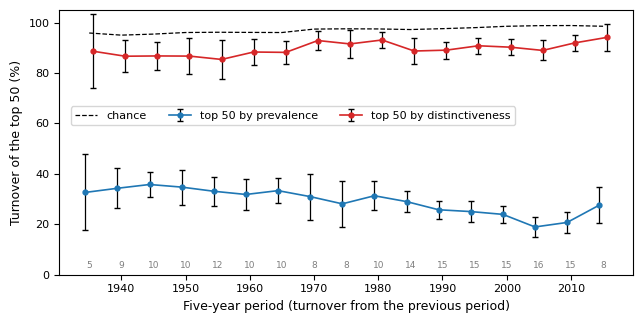

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_turnover_by_period.pdf')

In [4]:
bp = []
for (m, p), d in turn.groupby(['measure', 'period']):
    lo, hi = mean_ci(d['turnover'])
    bp.append({'measure': m, 'period': p, 'turnover': d['turnover'].mean(), 'lo': lo, 'hi': hi,
               'chance': d['chance'].mean(), 'n_genres': len(d)})
bp = pd.DataFrame(bp)
bp.to_csv(OUT / 'turnover_by_period.csv', index=False)
out('\nTurnover by period (mean over genres):')
for p, d in bp.groupby('period'):
    pv = d.set_index('measure')
    out(f'  {p}: prevalence {pv.loc["prevalence","turnover"]:.2f}  distinctiveness {pv.loc["distinctiveness","turnover"]:.2f}'
        f'  chance {pv["chance"].iloc[0]:.2f}  ({int(pv["n_genres"].iloc[0])} genres)')
for m in MCOL:
    d = bp[(bp['measure'] == m) & (bp['n_genres'] >= 3)].nlargest(3, 'turnover')
    out(f'  highest mean {m} turnover (periods with 3+ genres): ' + ', '.join(f'{int(r.period)} ({r.turnover:.2f})' for r in d.itertuples()))

MIN_G_PLOT = 3
bpp = bp[bp['n_genres'] >= MIN_G_PLOT]
fig, ax = plt.subplots(figsize=S.size(1.0, 3.3))
for i, m in enumerate(MCOL):
    d = bpp[bpp['measure'] == m].sort_values('period')
    off = (-0.6 if i == 0 else 0.6)
    ax.errorbar(d['period'] + off, 100 * d['turnover'], yerr=[100 * (d['turnover'] - d['lo']), 100 * (d['hi'] - d['turnover'])],
                fmt='o-', ms=3.5, lw=1.2, color=MCOLOR[m], label=f'top 50 by {m}', ecolor=S.INK, elinewidth=0.9, capsize=2)
ch = bpp[bpp['measure'] == 'prevalence'].sort_values('period')
ax.plot(ch['period'], 100 * ch['chance'], ls='--', color=S.INK, lw=0.9, label='chance')
for r in ch.itertuples():
    ax.text(r.period, 2, str(int(r.n_genres)), ha='center', va='bottom', fontsize=6.5, color=S.NEUTRAL)
ax.set_ylim(0, 105); ax.set_xlabel('Five-year period (turnover from the previous period)')
ax.set_ylabel('Turnover of the top 50 (%)')
ax.set_xticks(range(1940, int(bpp['period'].max()) + 1, 10))
ax.legend(loc='center left', bbox_to_anchor=(0.01, 0.6), ncol=3, frameon=True)
S.save(fig, 'fig_turnover_by_period', FIG)

## Figure: change points

For each genre and measure, the periods whose turnover is in the genre's top decile (its two highest if it has fewer than ten turnover values; its only value if it has one). Genres run along the bottom and periods up the side; blue dots are change points of the top 50 by prevalence, red dots of the top 50 by distinctiveness.


Change points (genres sharing each period):
  prevalence      1920: 1 genres (Drama)
  prevalence      1925: 1 genres (Drama)
  prevalence      1930: 1 genres (Comedy)
  prevalence      1935: 2 genres (Crime, Music)
  prevalence      1940: 2 genres (Action, Family)
  prevalence      1945: 3 genres (Animation, Romance, Thriller)
  prevalence      1950: 4 genres (Adventure, Comedy, Family, Romance)
  prevalence      1955: 5 genres (Animation, Music, Mystery, Thriller, Western)
  prevalence      1960: 1 genres (Horror)
  prevalence      1965: 1 genres (Adventure)
  prevalence      1970: 2 genres (Action, Horror)
  prevalence      1975: 1 genres (Crime)
  prevalence      1980: 1 genres (Science Fiction)
  prevalence      1985: 2 genres (Fantasy, History)
  prevalence      1995: 1 genres (Science Fiction)
  prevalence      2005: 1 genres (War)
  prevalence      2010: 1 genres (History)
  prevalence      2015: 1 genres (Fantasy)
  distinctiveness 1930: 1 genres (Comedy)
  distinctiveness 19

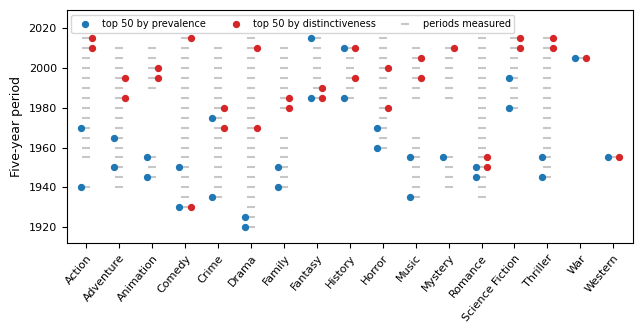

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_change_points.pdf')

In [5]:
cps = []
for (m, g), d in turn.groupby(['measure', 'genre']):
    k = max(1, int(np.ceil(0.1 * len(d)))) if len(d) >= 10 else min(2, len(d))
    for r in d.nlargest(k, 'turnover').itertuples():
        cps.append({'measure': m, 'genre': g, 'period': r.period, 'turnover': r.turnover, 'n_pairs': len(d)})
cps = pd.DataFrame(cps)
cps.to_csv(OUT / 'change_points.csv', index=False)
out('\nChange points (genres sharing each period):')
for m in MCOL:
    c = cps[cps['measure'] == m].groupby('period')['genre'].apply(lambda s: ', '.join(sorted(s)))
    for p, gs in c.items():
        out(f'  {m:<15} {p}: {len(gs.split(", "))} genres ({gs})')
for m in MCOL:
    d = cps[cps['measure'] == m]
    out(f'  {m}: change points in {d["genre"].nunique()} genres; share in 2000 or later: {(d["period"] >= 2000).mean():.2f};'
        f' share 1960-1979: {d["period"].between(1960, 1979).mean():.2f}; share before 1960: {(d["period"] < 1960).mean():.2f}')

GX = {g: i for i, g in enumerate(GENRES)}
fig, ax = plt.subplots(figsize=S.size(1.0, 3.4))
for m, off in [('prevalence', -0.17), ('distinctiveness', 0.17)]:
    d = cps[cps['measure'] == m]
    ax.scatter([GX[g] + off for g in d['genre']], d['period'], s=18, color=MCOLOR[m], label=f'top 50 by {m}', zorder=3)
# light gray marks: the periods each genre could have a change point in (consecutive qualifying periods)
av = turn[turn['measure'] == 'prevalence']
ax.scatter([GX[g] for g in av['genre']], av['period'], marker='_', s=40, color=S.LIGHT, zorder=1, label='periods measured')
ax.set_xticks(range(len(GENRES))); ax.set_xticklabels(GENRES, rotation=50, ha='right', rotation_mode='anchor')
ax.set_ylabel('Five-year period'); ax.set_xlim(-0.6, len(GENRES) - 0.4)
ax.legend(loc='upper left', ncol=3, frameon=True, fontsize=7)
ax.set_ylim(cps['period'].min() - 8, cps['period'].max() + 14)
S.save(fig, 'fig_change_points', FIG)

## Supplement: turnover genre by genre

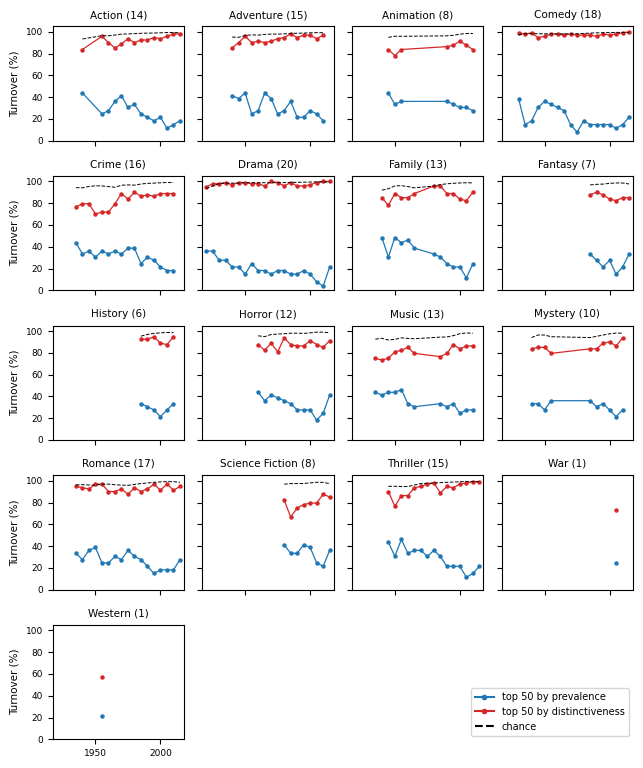

PosixPath('/Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Docs/Writing/manuscript/Scene A Faire Computational/figures/fig_app_turnover_by_genre.pdf')

In [6]:
gl = [g for g in GENRES]
ncol = 4; nrow = int(np.ceil(len(gl) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(S.TEXT_WIDTH_IN, 1.55 * nrow), sharex=True, sharey=True)
xmin, xmax = int(turn['period'].min()) - 3, int(turn['period'].max()) + 3
for ax, g in zip(axes.flat, gl):
    for m in MCOL:
        d = turn[(turn['measure'] == m) & (turn['genre'] == g)].sort_values('period')
        ax.plot(d['period'], 100 * d['turnover'], 'o-', ms=2.2, lw=0.9, color=MCOLOR[m])
    d = turn[(turn['measure'] == 'prevalence') & (turn['genre'] == g)].sort_values('period')
    ax.plot(d['period'], 100 * d['chance'], ls='--', lw=0.7, color=S.INK)
    ax.set_title(f'{g} ({len(d)})', fontsize=7.5); ax.set_ylim(0, 105); ax.set_xlim(xmin, xmax)
    ax.tick_params(labelsize=6.5)
for ax in axes.flat[len(gl):]:
    ax.axis('off')
for ax in axes[:, 0]:
    ax.set_ylabel('Turnover (%)', fontsize=7.5)
fig.legend(handles=[plt.Line2D([], [], color=S.PREVALENCE, marker='o', ms=3, label='top 50 by prevalence'),
                    plt.Line2D([], [], color=S.DISTINCTIVENESS, marker='o', ms=3, label='top 50 by distinctiveness'),
                    plt.Line2D([], [], color=S.INK, ls='--', label='chance')],
           loc='lower right', bbox_to_anchor=(0.98, 0.04), fontsize=7, frameon=True)
S.save(fig, 'fig_app_turnover_by_genre', FIG)

## Check: does corpus growth produce the pattern?

For each genre, every qualifying period is subsampled to the genre's smallest qualifying period size (films of the genre), and the period's other films are subsampled at the same rate, so the genre's share of the period is kept. Both measures are recomputed from the film-level element lists of Notebook 02 (narrative elements only, each counted once per film): prevalence is the share of the sampled genre films with the element, and distinctiveness is (f(e, g) + α · p_g) / (f(e) + α) with α = 1 and p_g the genre's share of the sampled film-genre pairs. The eligibility and top-50 rules are as above, except that a period needs at least 100 eligible elements after subsampling. Five seeds. The same code is also run without subsampling, to show it reproduces the Notebook 08 values.

In [7]:
union = read_parquet(V4 / '01c_union' / 'movies_union.parquet', columns=['union_id', 'year', 'genres_canonical']).dropna(subset=['year'])
union['bin'] = (union['year'] // 5 * 5).astype(int)
union['genres'] = union['genres_canonical'].apply(list)
ei = read_parquet(V4 / '02_elements' / 'element_index.parquet')
ei = ei[[k in NARR for k in zip(ei['element'], ei['element_type'])]].drop_duplicates(['union_id', 'element', 'element_type'])
ei['key'] = ei['element'] + '\t' + ei['element_type']   # string keys keep the pandas index flat
qbins = sorted({b for (_, b) in QUAL})
films_by_bin = {b: union[union['bin'] == b] for b in qbins}
occ_by_bin = {b: ei[ei['union_id'].isin(films_by_bin[b]['union_id'])][['union_id', 'key']] for b in qbins}
out(f'\nfilm-level occurrences in qualifying periods: {sum(len(v) for v in occ_by_bin.values()):,}')

def period_scores(g, b, frac_g=None, n_g=None, rng=None):
    f = films_by_bin[b]
    in_g = f['genres'].apply(lambda gs: g in gs)
    fg, fo = f[in_g], f[~in_g]
    if n_g is not None:
        rate = n_g / len(fg)
        fg = fg.sample(n=n_g, random_state=rng)
        fo = fo.sample(n=int(round(rate * len(fo))), random_state=rng)
    ids = set(fg['union_id']) | set(fo['union_id'])
    occ = occ_by_bin[b]; occ = occ[occ['union_id'].isin(ids)]
    f_e = occ.groupby('key').size()
    f_eg = occ[occ['union_id'].isin(set(fg['union_id']))].groupby('key').size()
    pairs = pd.concat([fg['genres'], fo['genres']]).explode()
    p_g = (pairs == g).mean()
    d = pd.DataFrame({'f_eg': f_eg}).join(f_e.rename('f_e'))
    d = d[d['f_eg'] >= MIN_E]
    d['prevalence'] = d['f_eg'] / len(fg)
    d['distinctiveness'] = (d['f_eg'] + ALPHA * p_g) / (d['f_e'] + ALPHA)
    return d

# reproduction check without subsampling, on a few genre-periods
rep = []
for (g, b) in sorted(QUAL)[:: max(1, len(QUAL) // 12)][:12]:
    d = period_scores(g, b)
    ref = elig[(elig['genre'] == g) & (elig['bin'] == b)].copy()
    ref.index = ref['element'] + '\t' + ref['element_type']
    j = d.join(ref[['rel_freq_in_genre', 'posterior_smoothed']], how='inner')
    rep.append({'genre': g, 'bin': b, 'n': len(j),
                'rho_prev': spearmanr(j['prevalence'], j['rel_freq_in_genre'])[0],
                'rho_dist': spearmanr(j['distinctiveness'], j['posterior_smoothed'])[0]})
rep = pd.DataFrame(rep)
out(f'reproduction of Notebook 08 without subsampling (12 genre-periods): median Spearman prevalence {rep["rho_prev"].median():.3f},'
    f' distinctiveness {rep["rho_dist"].median():.3f}')

SEEDS = [20260219 + i for i in range(5)]
eq_rows = []
for g in GENRES:
    gq = sorted(b for (gg, b) in QUAL if gg == g)
    if len(gq) < 2:
        continue
    n_min = int(min(nbg[(g, b)] for b in gq))
    for seed in SEEDS:
        rng = np.random.RandomState(seed)
        tp, es = {m: {} for m in MCOL}, {}
        for b in gq:
            d = period_scores(g, b, n_g=n_min, rng=rng)
            if len(d) < 100:
                continue
            es[(g, b)] = set(d.index)
            for m in MCOL:
                tp[m][(g, b)] = set(d.nlargest(TOP, m).index)
        t = turnover_table(tp, es)
        if len(t):
            t['seed'] = seed; t['n_min'] = n_min
            eq_rows.append(t)
eq = pd.concat(eq_rows, ignore_index=True)
eq.to_csv(OUT / 'turnover_equal_size.csv', index=False)
eqm = eq.groupby(['measure', 'genre', 'period'], as_index=False)[['turnover', 'chance']].mean()
both = eqm.merge(turn, on=['measure', 'genre', 'period'], suffixes=('_eq', '_full'))
out('\nEqual-size check (mean over five seeds):')
for m in MCOL:
    a = eqm[eqm['measure'] == m]; b2 = both[both['measure'] == m]
    out(f'  {m:<15} mean turnover {a["turnover"].mean():.3f} (full data, same pairs: {b2["turnover_full"].mean():.3f});'
        f' Spearman with full-data turnover across genre-periods {spearmanr(b2["turnover_eq"], b2["turnover_full"])[0]:.2f} (n = {len(b2)})')
gap_eq = (eqm[eqm['measure'] == 'distinctiveness'].set_index(['genre', 'period'])['turnover']
          - eqm[eqm['measure'] == 'prevalence'].set_index(['genre', 'period'])['turnover']).dropna()
out(f'  distinctiveness minus prevalence turnover, equal size: mean {gap_eq.mean():.3f}; positive in {(gap_eq > 0).mean():.0%} of genre-periods')
for m in MCOL:
    a = eqm[eqm['measure'] == m]
    early, late = a[a['period'] < 2000]['turnover'], a[a['period'] >= 2000]['turnover']
    f = turn[turn['measure'] == m]
    out(f'  {m:<15} before 2000 / 2000 on: equal size {early.mean():.3f} / {late.mean():.3f};'
        f' full data {f[f["period"] < 2000]["turnover"].mean():.3f} / {f[f["period"] >= 2000]["turnover"].mean():.3f}')


film-level occurrences in qualifying periods: 2,347,016


reproduction of Notebook 08 without subsampling (12 genre-periods): median Spearman prevalence 1.000, distinctiveness 1.000



Equal-size check (mean over five seeds):
  prevalence      mean turnover 0.384 (full data, same pairs: 0.284); Spearman with full-data turnover across genre-periods 0.65 (n = 194)
  distinctiveness mean turnover 0.874 (full data, same pairs: 0.897); Spearman with full-data turnover across genre-periods 0.86 (n = 194)
  distinctiveness minus prevalence turnover, equal size: mean 0.489; positive in 100% of genre-periods
  prevalence      before 2000 / 2000 on: equal size 0.392 / 0.366; full data 0.309 / 0.221
  distinctiveness before 2000 / 2000 on: equal size 0.876 / 0.868; full data 0.892 / 0.909


## Robustness: is the turnover of the distinctiveness ranking a small-count effect?

The top of a ranking by distinctiveness can be filled by elements seen in only a handful of the genre's films in a period, whose distinctiveness is close to 1 by chance. This section repeats both analyses with the eligible pool restricted, at each genre and period, to elements in at least k of the genre's films in that period, for k = 5, 10, and 20, applying the same restriction to prevalence so the comparison is fair. A genre-period qualifies if the genre has at least 100 films in it and at least 100 elements pass the restriction (twice the top 50). Chance is computed for the restricted pools: with n₁ and n₂ eligible elements and c eligible in both periods, two random top 50s are expected to share c · 50 · 50 / (n₁ n₂) elements, so chance survival is that overlap divided by 50 and chance turnover is 1 minus the corresponding Jaccard.

In [8]:
KS, LAGS_R, MIN_ELIG_K = [5, 10, 20], [20, 50], 100
rob_rows, keep_tops = [], {}
for k in KS:
    ek = bins[(bins['film_count'] >= k) & (bins['N_bg'] >= MIN_GENRE_FILMS)]
    nk = ek.groupby(['genre', 'bin']).size()
    qk = set(nk[nk >= MIN_ELIG_K].index)
    ek = ek[[x in qk for x in zip(ek['genre'], ek['bin'])]]
    es = {(g, b): set(zip(d['element'], d['element_type'])) for (g, b), d in ek.groupby(['genre', 'bin'])}
    tk = {m: {(g, b): set(zip(d.nlargest(TOP, c)['element'], d.nlargest(TOP, c)['element_type']))
              for (g, b), d in ek.groupby(['genre', 'bin'])} for m, c in MCOL.items()}
    keep_tops[k] = (tk, es)
    tt = turnover_table(tk, es)
    for m in MCOL:
        row = {'k': k, 'measure': m, 'genre_periods': len(qk), 'genres': len({g for g, _ in qk}),
               'pairs': int((tt['measure'] == m).sum()),
               'turnover': tt.loc[tt['measure'] == m, 'turnover'].mean(), 'chance_turnover': tt.loc[tt['measure'] == m, 'chance'].mean()}
        for lag in LAGS_R:
            gv, gc = [], []
            for g in sorted({g for g, _ in qk}):
                vals, ch = [], []
                for b in sorted(b for gg, b in qk if gg == g):
                    b2 = b + lag
                    if (g, b2) in tk[m]:
                        n1, n2 = len(es[(g, b)]), len(es[(g, b2)]); c = len(es[(g, b)] & es[(g, b2)])
                        vals.append(len(tk[m][(g, b)] & tk[m][(g, b2)]) / TOP)
                        ch.append(c * TOP / (n1 * n2))
                if vals:
                    gv.append(np.mean(vals)); gc.append(np.mean(ch))
            row[f'survival{lag}'] = np.mean(gv) if gv else np.nan
            row[f'chance{lag}'] = np.mean(gc) if gc else np.nan
            row[f'genres{lag}'] = len(gv)
        rob_rows.append(row)
rob = pd.DataFrame(rob_rows)
rob.to_csv(OUT / 'robustness_min_films.csv', index=False)
out('\nRobustness: eligible pool restricted to elements in at least k of the genre\'s films in the period')
out('  k   measure          genre-periods (genres)  pairs  turnover  chance   surv20  ch20   surv50  ch50   (genres at 20/50 yrs)')
for r in rob.itertuples():
    out(f'  {r.k:<3} {r.measure:<16} {r.genre_periods:>5} ({r.genres:>2})             {r.pairs:>4}   {r.turnover:.3f}    {r.chance_turnover:.3f}   '
        f'{r.survival20:.3f}  {r.chance20:.3f}  {r.survival50:.3f}  {r.chance50:.3f}  ({r.genres20}/{r.genres50})')
# turnover relative to chance: the share of the way from a fixed top 50 (0) to chance
for r in rob.itertuples():
    out(f'  k = {r.k:<2} {r.measure:<15} turnover as a share of chance turnover: {r.turnover / r.chance_turnover:.2f};'
        f' survival at 20 years as a multiple of chance: {r.survival20 / r.chance20:.1f}')

# Examples at k = 20: distinctive elements that persist across eras, and ones that come and go
tk20, es20 = keep_tops[20]
out('\nExamples at k = 20 (top 50 by distinctiveness):')
for g in ['Horror', 'Science Fiction', 'Crime', 'Western', 'Comedy', 'War']:
    periods = sorted(b for gg, b in tk20['distinctiveness'] if gg == g)
    if len(periods) < 3:
        continue
    cnt, elig_cnt = {}, {}
    for b in periods:
        for e in tk20['distinctiveness'][(g, b)]:
            cnt[e] = cnt.get(e, 0) + 1
        for e in es20[(g, b)]:
            elig_cnt[e] = elig_cnt.get(e, 0) + 1
    persist = sorted(cnt, key=lambda e: -cnt[e])[:6]
    come_go = [e for e in cnt if cnt[e] == 1 and elig_cnt.get(e, 0) >= max(3, len(periods) // 2)]
    come_go = sorted(come_go, key=lambda e: -elig_cnt[e])[:6]
    out(f'  {g} ({len(periods)} periods, {periods[0]}-{periods[-1]}):')
    out('    persist: ' + ', '.join(f'{e[0]} ({cnt[e]}/{len(periods)})' for e in persist))
    out('    once in the top 50 though eligible in many periods: ' + ', '.join(f'{e[0]} (eligible {elig_cnt[e]})' for e in come_go))


Robustness: eligible pool restricted to elements in at least k of the genre's films in the period
  k   measure          genre-periods (genres)  pairs  turnover  chance   surv20  ch20   surv50  ch50   (genres at 20/50 yrs)
  5   prevalence         225 (17)              196   0.287    0.972   0.786  0.051  0.696  0.042  (15/15)
  5   distinctiveness    225 (17)              196   0.897    0.972   0.137  0.051  0.098  0.042  (15/15)
  10  prevalence         206 (17)              175   0.273    0.936   0.802  0.107  0.686  0.094  (15/14)
  10  distinctiveness    206 (17)              175   0.803    0.936   0.222  0.107  0.166  0.094  (15/14)
  20  prevalence         114 (15)               96   0.220    0.920   0.838  0.127  0.757  0.107  (10/3)
  20  distinctiveness    114 (15)               96   0.751    0.920   0.276  0.127  0.158  0.107  (10/3)
  k = 5  prevalence      turnover as a share of chance turnover: 0.29; survival at 20 years as a multiple of chance: 15.5
  k = 5  distinctive

## Report

In [9]:
rule = ['Rule: five-year periods; a period qualifies for a genre with at least 100 of the genre\'s films and at least 150 eligible',
        'elements (narrative elements in at least 5 of the genre\'s films in the period); top 50 by prevalence (rel_freq_in_genre)',
        'and by distinctiveness (posterior_smoothed, alpha = 1) from Notebook 08; turnover = 1 - Jaccard between the top 50s of',
        'consecutive qualifying periods, dated to the later period; change points = periods in a genre\'s top decile of turnover',
        '(its two highest if fewer than ten values). Chance = turnover of two random top 50s from the eligible elements.', '']
(OUT / 'report.txt').write_text('\n'.join(rule + report) + '\n')
print('wrote', OUT / 'report.txt')

wrote /Users/<you>/Library/CloudStorage/GoogleDrive-<you>/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild/16c_manuscript_figures/report.txt
